In [1]:
!nvidia-smi

Thu Oct 22 11:42:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import numpy as np
import time

N = 1024

A_cpu = np.random.rand(N, N).astype(np.float32)
B_cpu = np.random.rand(N, N).astype(np.float32)

start = time.time()

C_cpu = np.matmul(A_cpu, B_cpu)

end = time.time()

print(f"Mnożenie macierzy na CPU trwało: {end - start:.5f} sekund.")

Mnożenie macierzy na CPU trwało: 0.02379 sekund.


In [3]:
import cupy as cp

A_gpu = cp.array(A_cpu)
B_gpu = cp.array(B_cpu)

start = time.time()

C_gpu = cp.matmul(A_gpu, B_gpu)

cp.cuda.Stream.null.synchronize()

end = time.time()

print(f"Mnożenie macierzy na GPU trwało: {end - start:.5f} sekund.")

Mnożenie macierzy na GPU trwało: 0.10900 sekund.


In [4]:
C_gpu_cpu = cp.asnumpy(C_gpu)

print("Czy wyniki są zgodne?",
      np.allclose(C_cpu, C_gpu_cpu, rtol=1e-3, atol=1e-3))

Czy wyniki są zgodne? True


In [5]:
import locale
locale.getpreferredencoding = lambda: "UTF-8"

!pip install pycuda

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 33.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 101.8/101.8 kB 11.7 MB/s eta 0:00:00
  Created wheel for pycuda: filename=pycuda-2026.1-cp313-cp313-linux_x86_64.whl size=5281393 sha256=669ffe8cd34ce2d08ee6d44170d9696eddf1900c507c98678792add86c72221c
  Stored in directory: /root/.cache/pip/wheels/ce/26/46/c519675fcb0e5e17bab8e85b6676528c40d12d794182340e85
Successfully built pycuda


In [6]:
kernel_code = """
__global__ void matrixMul(float *A, float *B, float *C, int N) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;

    float sum = 0.0;

    if (row < N && col < N) {
        for (int k = 0; k < N; k++) {
            sum += A[row * N + k] * B[k * N + col];
        }

        C[row * N + col] = sum;
    }
}
"""

In [7]:
import pycuda.driver as cuda
import pycuda.autoinit
from pycuda.compiler import SourceModule

mod = SourceModule(kernel_code)
matrixMul = mod.get_function("matrixMul")

C_cuda_cpu = np.empty((N, N), np.float32)

A_dev = cuda.mem_alloc(A_cpu.nbytes)
B_dev = cuda.mem_alloc(B_cpu.nbytes)
C_dev = cuda.mem_alloc(C_cuda_cpu.nbytes)

cuda.memcpy_htod(A_dev, A_cpu)
cuda.memcpy_htod(B_dev, B_cpu)

block_size = (32, 32, 1)
grid_size = ((N + 31) // 32, (N + 31) // 32, 1)

start = time.time()

matrixMul(
    A_dev, B_dev, C_dev, np.int32(N),
    block=block_size,
    grid=grid_size
)

cuda.Context.synchronize()

end = time.time()

cuda.memcpy_dtoh(C_cuda_cpu, C_dev)

print(f"Mnożenie macierzy CUDA trwało: {end - start:.5f} sekund.")

print("Czy wyniki są zgodne?",
      np.allclose(C_cpu, C_cuda_cpu, rtol=1e-3, atol=1e-3))

del A_dev, B_dev, C_dev

Mnożenie macierzy CUDA trwało: 0.00741 sekund.
Czy wyniki są zgodne? True


In [8]:
import numpy as np
import cupy as cp
import pycuda.driver as cuda
import pycuda.autoinit
import matplotlib.pyplot as plt
import time

rozmiary = [128, 256, 512, 1024, 2048]

czasy_cpu = []
czasy_cupy = []
czasy_pycuda = []

dane = {}

for n in rozmiary:
    A = np.random.rand(n, n).astype(np.float32)
    B = np.random.rand(n, n).astype(np.float32)
    dane[n] = (A, B)

# 1. CPU - NumPy

for n in rozmiary:
    A, B = dane[n]

    np.matmul(A, B)

    pomiary = []

    for i in range(3):
        start = time.perf_counter()

        C = np.matmul(A, B)

        end = time.perf_counter()
        pomiary.append(end - start)

    czasy_cpu.append(np.median(pomiary))

# 2. GPU - CuPy

cuda.Context.pop()

try:
    for n in rozmiary:
        A, B = dane[n]

        A_gpu = cp.asarray(A)
        B_gpu = cp.asarray(B)

        cp.matmul(A_gpu, B_gpu)
        cp.cuda.Stream.null.synchronize()

        pomiary = []

        for i in range(3):
            start = time.perf_counter()

            C_gpu = cp.matmul(A_gpu, B_gpu)
            cp.cuda.Stream.null.synchronize()

            end = time.perf_counter()
            pomiary.append(end - start)

        czasy_cupy.append(np.median(pomiary))

        del A_gpu, B_gpu, C_gpu

finally:
    pycuda.autoinit.context.push()

# 3. GPU - PyCUDA

for n in rozmiary:
    A, B = dane[n]

    C = np.empty((n, n), dtype=np.float32)


    A_dev = cuda.mem_alloc(A.nbytes)
    B_dev = cuda.mem_alloc(B.nbytes)
    C_dev = cuda.mem_alloc(C.nbytes)

    cuda.memcpy_htod(A_dev, A)
    cuda.memcpy_htod(B_dev, B)

    block_size = (32, 32, 1)
    grid_size = ((n + 31) // 32, (n + 31) // 32, 1)

    # Rozgrzewka
    matrixMul(
        A_dev, B_dev, C_dev, np.int32(n),
        block=block_size, grid=grid_size
    )
    cuda.Context.synchronize()

    pomiary = []

    for i in range(3):
        start = time.perf_counter()

        matrixMul(
            A_dev, B_dev, C_dev, np.int32(n),
            block=block_size, grid=grid_size
        )

        cuda.Context.synchronize()

        end = time.perf_counter()
        pomiary.append(end - start)

    czasy_pycuda.append(np.median(pomiary))

    # Zwolnienie pamięci GPU
    del A_dev, B_dev, C_dev

# 4. Wyświetlenie wyników

print("Rozmiar | CPU (s) | CuPy (s) | PyCUDA (s)")
print("-" * 50)

for i, n in enumerate(rozmiary):
    print(
        f"{n:7} | "
        f"{czasy_cpu[i]:.6f} | "
        f"{czasy_cupy[i]:.6f} | "
        f"{czasy_pycuda[i]:.6f}"
    )

Rozmiar | CPU (s) | CuPy (s) | PyCUDA (s)
--------------------------------------------------
    128 | 0.000058 | 0.000061 | 0.000056
    256 | 0.000313 | 0.000104 | 0.000151
    512 | 0.002404 | 0.000202 | 0.000912
   1024 | 0.019769 | 0.000959 | 0.006782
   2048 | 0.147539 | 0.006118 | 0.053640


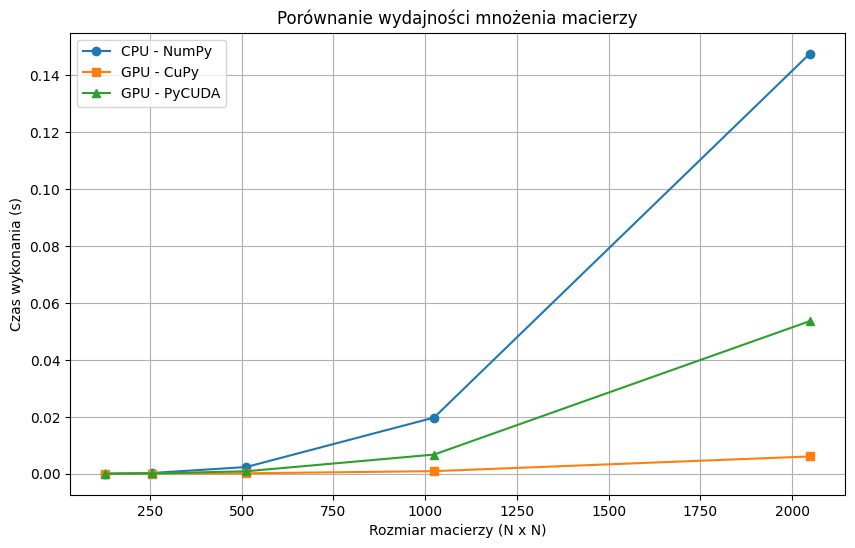

In [9]:
plt.figure(figsize=(10, 6))

plt.plot(rozmiary, czasy_cpu, 'o-', label='CPU - NumPy')
plt.plot(rozmiary, czasy_cupy, 's-', label='GPU - CuPy')
plt.plot(rozmiary, czasy_pycuda, '^-', label='GPU - PyCUDA')

plt.xlabel('Rozmiar macierzy (N x N)')
plt.ylabel('Czas wykonania (s)')

plt.title('Porównanie wydajności mnożenia macierzy')

plt.legend()
plt.grid(True)

plt.show()